# TUGAS KELOMPOK 6 " Simulator Data Hazards "

Anggota Kelompok:
- Mochammad Fery Ardiansyah "51240010" (Implementasi RAW)
- Ahmad Irwansyah "51240020" (Implementasi WAW dan Pengujian akhir)
- Yohanes Kriswanto Nyahu "51240044" (Implementasi WAR)

In [ ]:
# Simulator from https://github.com/harshitasingh4863/instruction-level-parallelism-simulator.git

from dataclasses import dataclass


@dataclass
class Instruction:
    name: str
    destination: str
    sources: list


# -------------------------------------------------
# Sample Instruction Set
# -------------------------------------------------

instructions = [
    Instruction("I1", "R1", ["R2", "R3"]),
    Instruction("I2", "R4", ["R5", "R6"]),
    Instruction("I3", "R7", ["R1", "R4"]),
    Instruction("I4", "R8", ["R9", "R10"]),
    Instruction("I5", "R11", ["R7", "R8"]),
    Instruction("I6", "R12", ["R13", "R14"]),
]


# -------------------------------------------------
# Function to check dependency
# -------------------------------------------------

def has_dependency(inst1, inst2):
    """
    Returns True if inst2 depends on inst1.
    """

    # RAW dependency:
    # inst2 reads a register written by inst1
    if inst1.destination in inst2.sources:
        return True

    return False


# -------------------------------------------------
# Sequential Execution
# -------------------------------------------------

def sequential_execution(instructions):
    print("\n" + "=" * 50)
    print("SEQUENTIAL EXECUTION")
    print("=" * 50)

    cycle = 0

    for instruction in instructions:
        cycle += 1

        print(
            f"Cycle {cycle}: Executing {instruction.name} "
            f"({instruction.destination} = "
            f"{' + '.join(instruction.sources)})"
        )

    print(f"\nTotal Sequential Cycles: {cycle}")

    return cycle


# -------------------------------------------------
# ILP / Parallel Execution
# -------------------------------------------------

def parallel_execution(instructions):
    print("\n" + "=" * 50)
    print("INSTRUCTION-LEVEL PARALLEL EXECUTION")
    print("=" * 50)

    completed = set()
    remaining = instructions.copy()

    cycle = 0

    while remaining:

        cycle += 1
        current_cycle = []

        for instruction in remaining:

            # Check whether all previous dependencies
            # have already been completed

            dependencies_satisfied = True

            for previous in instructions:

                if previous.name == instruction.name:
                    break

                if has_dependency(previous, instruction):
                    if previous.name not in completed:
                        dependencies_satisfied = False
                        break

            if dependencies_satisfied:
                current_cycle.append(instruction)

        # Execute all independent instructions
        # in the same cycle

        print(f"\nCycle {cycle}:")

        for instruction in current_cycle:
            print(
                f"  -> {instruction.name}: "
                f"{instruction.destination} = "
                f"{' + '.join(instruction.sources)}"
            )

        # Mark instructions as completed

        for instruction in current_cycle:
            completed.add(instruction.name)
            remaining.remove(instruction)

    print(f"\nTotal ILP Cycles: {cycle}")

    return cycle


# -------------------------------------------------
# Dependency Analysis
# -------------------------------------------------

def show_dependencies(instructions):

    print("\n" + "=" * 50)
    print("DEPENDENCY ANALYSIS")
    print("=" * 50)

    found = False

    for i in range(len(instructions)):

        for j in range(i + 1, len(instructions)):

            if has_dependency(instructions[i], instructions[j]):

                print(
                    f"{instructions[j].name} depends on "
                    f"{instructions[i].name} "
                    f"(Register: {instructions[i].destination})"
                )

                found = True

    if not found:
        print("No dependencies found.")


# -------------------------------------------------
# Main Program
# -------------------------------------------------

def main():

    print("\n")
    print("*" * 60)
    print("      INSTRUCTION-LEVEL PARALLELISM SIMULATOR")
    print("*" * 60)

    print("\nInstruction Set:")

    for instruction in instructions:
        print(
            f"{instruction.name}: "
            f"{instruction.destination} = "
            f"{' + '.join(instruction.sources)}"
        )

    # Show dependencies

    show_dependencies(instructions)

    # Sequential execution

    sequential_cycles = sequential_execution(instructions)

    # Parallel execution

    parallel_cycles = parallel_execution(instructions)

    # Calculate speedup

    speedup = sequential_cycles / parallel_cycles

    efficiency = speedup / len(instructions) * 100

    print("\n" + "=" * 50)
    print("PERFORMANCE COMPARISON")
    print("=" * 50)

    print(f"Sequential Cycles : {sequential_cycles}")
    print(f"ILP Cycles        : {parallel_cycles}")
    print(f"Speedup            : {speedup:.2f}x")
    print(f"ILP Efficiency     : {efficiency:.2f}%")

    print("\nConclusion:")
    print(
        "ILP reduces execution cycles by allowing "
        "independent instructions to execute in parallel."
    )


# -------------------------------------------------
# Run Program
# -------------------------------------------------

if __name__ == "__main__":
    main()




************************************************************
      INSTRUCTION-LEVEL PARALLELISM SIMULATOR
************************************************************

Instruction Set:
I1: R1 = R2 + R3
I2: R4 = R5 + R6
I3: R7 = R1 + R4
I4: R8 = R9 + R10
I5: R11 = R7 + R8
I6: R12 = R13 + R14

DEPENDENCY ANALYSIS
I3 depends on I1 (Register: R1)
I3 depends on I2 (Register: R4)
I5 depends on I3 (Register: R7)
I5 depends on I4 (Register: R8)

SEQUENTIAL EXECUTION
Cycle 1: Executing I1 (R1 = R2 + R3)
Cycle 2: Executing I2 (R4 = R5 + R6)
Cycle 3: Executing I3 (R7 = R1 + R4)
Cycle 4: Executing I4 (R8 = R9 + R10)
Cycle 5: Executing I5 (R11 = R7 + R8)
Cycle 6: Executing I6 (R12 = R13 + R14)

Total Sequential Cycles: 6

INSTRUCTION-LEVEL PARALLEL EXECUTION

Cycle 1:
  -> I1: R1 = R2 + R3
  -> I2: R4 = R5 + R6
  -> I4: R8 = R9 + R10
  -> I6: R12 = R13 + R14

Cycle 2:
  -> I3: R7 = R1 + R4

Cycle 3:
  -> I5: R11 = R7 + R8

Total ILP Cycles: 3

PERFORMANCE COMPARISON
Sequential Cycles : 6
ILP Cyc

In [ ]:

# ============================================================
# SEL 2: FUNGSI ANALISIS DEPENDENCY DAN DEPENDENCY GRAPH
# ============================================================

import matplotlib.pyplot as plt


def analisis_dependency(inst1, inst2):
    """
    Menganalisis dependency antara dua instruksi berurutan.
    Mengembalikan jenis dependency yang ditemukan.
    """
    hasil = []

    # RAW: instruksi 2 membaca register yang ditulis instruksi 1
    if inst1.destination in inst2.sources:
        hasil.append("RAW")

    # WAR: instruksi 1 membaca register yang ditulis instruksi 2
    if inst2.destination in inst1.sources:
        hasil.append("WAR")

    # WAW: kedua instruksi menulis register tujuan yang sama
    if inst1.destination == inst2.destination:
        hasil.append("WAW")

    return hasil


def tampilkan_dependency(judul, inst1, inst2, target):
    """Menampilkan hasil analisis dependency."""
    hasil = analisis_dependency(inst1, inst2)

    print("=" * 55)
    print(judul)
    print("=" * 55)
    print(f"{inst1.name}: {inst1.destination} = "
          f"{' + '.join(inst1.sources)}")
    print(f"{inst2.name}: {inst2.destination} = "
          f"{' + '.join(inst2.sources)}")
    print("Dependency terdeteksi:", hasil)

    berhasil = target in hasil
    print(f"Pengujian {target}: {'LULUS' if berhasil else 'GAGAL'}")

    return berhasil


def buat_dependency_graph(judul, inst1, inst2, jenis, keterangan):
    """Membuat graph dua instruksi dengan panah ketergantungan."""

    fig, ax = plt.subplots(figsize=(10, 3.5))

    # Kotak instruksi pertama
    ax.text(
        0.22, 0.55,
        f"{inst1.name}\n{inst1.destination} = "
        f"{' + '.join(inst1.sources)}",
        ha="center", va="center", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.8",
                  facecolor="lightblue", edgecolor="black")
    )

    # Kotak instruksi kedua
    ax.text(
        0.78, 0.55,
        f"{inst2.name}\n{inst2.destination} = "
        f"{' + '.join(inst2.sources)}",
        ha="center", va="center", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.8",
                  facecolor="lightyellow", edgecolor="black")
    )

    # Panah menunjukkan urutan instruksi yang perlu dipertahankan
    ax.annotate(
        "",
        xy=(0.63, 0.55),
        xytext=(0.37, 0.55),
        arrowprops=dict(arrowstyle="->", lw=2)
    )

    ax.text(
        0.50, 0.76, jenis,
        ha="center", va="center",
        fontsize=12, fontweight="bold"
    )

    ax.text(
        0.50, 0.17, keterangan,
        ha="center", va="center",
        fontsize=9, wrap=True
    )

    ax.set_title(judul)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    plt.tight_layout()
    plt.show()


IMPLEMENTASI RAW - FERY
I1: R1 = R2 + R3
I2: R4 = R1 + R5
Dependency terdeteksi: ['RAW']
Pengujian RAW: LULUS


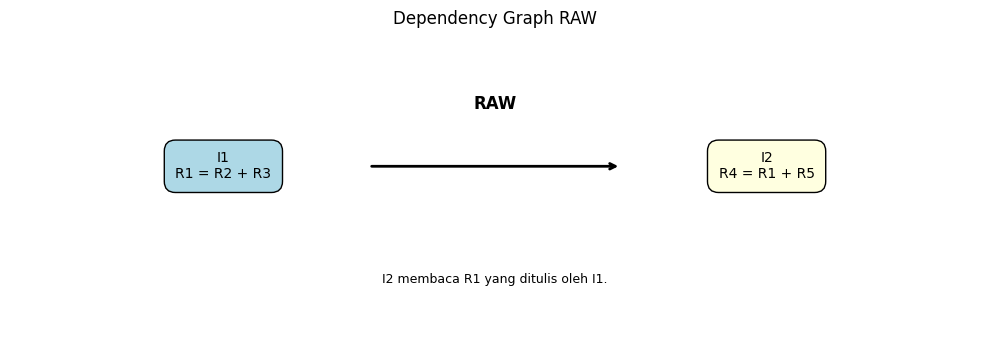

In [ ]:

# ============================================================
# SEL 3: IMPLEMENTASI RAW - FERY
# ============================================================

# I1 menulis R1
raw_i1 = Instruction("I1", "R1", ["R2", "R3"])

# I2 membaca R1 yang ditulis oleh I1
raw_i2 = Instruction("I2", "R4", ["R1", "R5"])

hasil_raw = tampilkan_dependency(
    "IMPLEMENTASI RAW - FERY",
    raw_i1,
    raw_i2,
    "RAW"
)

buat_dependency_graph(
    "Dependency Graph RAW",
    raw_i1,
    raw_i2,
    "RAW",
    "I2 membaca R1 yang ditulis oleh I1."
)


IMPLEMENTASI WAR - YOHANES
I1: R4 = R1 + R2
I2: R1 = R3 + R5
Dependency terdeteksi: ['WAR']
Pengujian WAR: LULUS


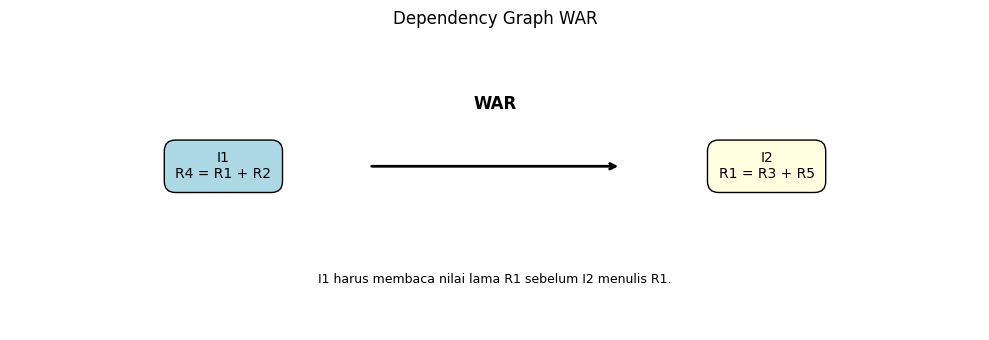

In [ ]:

# ============================================================
# SEL 4: IMPLEMENTASI WAR - YOHANES
# ============================================================

# I1 membaca R1
war_i1 = Instruction("I1", "R4", ["R1", "R2"])

# I2 kemudian menulis R1
war_i2 = Instruction("I2", "R1", ["R3", "R5"])

hasil_war = tampilkan_dependency(
    "IMPLEMENTASI WAR - YOHANES",
    war_i1,
    war_i2,
    "WAR"
)

buat_dependency_graph(
    "Dependency Graph WAR",
    war_i1,
    war_i2,
    "WAR",
    "I1 harus membaca nilai lama R1 sebelum I2 menulis R1."
)


IMPLEMENTASI WAW - IRWANSYAH
I1: R1 = R2 + R3
I2: R1 = R4 + R5
Dependency terdeteksi: ['WAW']
Pengujian WAW: LULUS


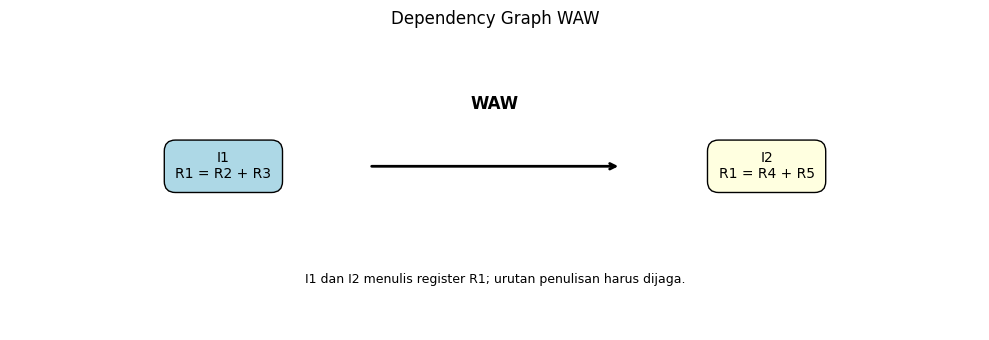

In [ ]:
# ============================================================
# SEL 5: IMPLEMENTASI WAW - IRWANSYAH
# ============================================================

# I1 menulis R1
waw_i1 = Instruction("I1", "R1", ["R2", "R3"])

# I2 juga menulis R1
waw_i2 = Instruction("I2", "R1", ["R4", "R5"])

hasil_waw = tampilkan_dependency(
    "IMPLEMENTASI WAW - IRWANSYAH",
    waw_i1,
    waw_i2,
    "WAW"
)

buat_dependency_graph(
    "Dependency Graph WAW",
    waw_i1,
    waw_i2,
    "WAW",
    "I1 dan I2 menulis register R1; urutan penulisan harus dijaga."
)

In [ ]:

# ============================================================
# SEL 6: PENGUJIAN AKHIR KELOMPOK - IRWANSYAH
# ============================================================

print("=" * 55)
print("PENGUJIAN AKHIR ILP: RAW, WAR, DAN WAW")
print("=" * 55)

hasil_pengujian = {
    "RAW": hasil_raw,
    "WAR": hasil_war,
    "WAW": hasil_waw
}

for jenis, status in hasil_pengujian.items():
    print(f"{jenis}: {'LULUS' if status else 'GAGAL'}")

if all(hasil_pengujian.values()):
    print("\nKESIMPULAN: Semua pengujian dependency berhasil.")
else:
    print("\nKESIMPULAN: Periksa kembali implementasi yang gagal.")


PENGUJIAN AKHIR ILP: RAW, WAR, DAN WAW
RAW: LULUS
WAR: LULUS
WAW: LULUS

KESIMPULAN: Semua pengujian dependency berhasil.
